In [8]:
!pip install pandas


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\User\AppData\Local\Python\pythoncore-3.15-64\python.exe -m pip install --upgrade pip


In [9]:
import pandas as pd 
df = pd.read_csv(
    r"C:\Users\User\Downloads\HR_Job_Placement_Dataset (1).csv"
)

print(df.shape)
df.head()

(51500, 26)


,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,...,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
0,27,Male,65.061656,83.842578,75.856526,Computer Science,58.221909,89.566305,64.474484,79.548913,...,5.805850,Tier 3,Not Matched,Medium,Not Required,15.0,No,18.0,Not Willing,Not Placed
1,24,Male,67.885626,64.973305,73.093588,Electronics,71.927978,54.591971,61.077306,73.316134,...,10.807739,Tier 1,Matched,High,Required,0.0,NaN,NaN,Not Willing,Not Placed
2,33,Female,73.892471,68.834121,90.196460,Information Technology,72.445041,58.587088,79.494739,75.466980,...,5.476839,Tier 3,Not Matched,Low,Not Required,0.0,No,3.0,Not Willing,Placed
3,31,Male,74.145568,76.255126,75.586731,Mechanical,78.855676,61.022065,53.740386,73.676449,...,9.980580,Tier 2,Matched,Low,Not Required,0.0,Yes,6.0,NaN,Not Placed
4,28,Male,60.475937,65.786336,80.801010,Information Technology,68.286776,65.713731,61.438314,88.994847,...,8.921233,Tier 2,Matched,Medium,Not Required,0.0,No,3.0,Willing,Not Placed


In [10]:
df.info()

df.describe()

df.dtypes

df.columns

<class 'pandas.DataFrame'>
RangeIndex: 51500 entries, 0 to 51499
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age_years                  51500 non-null  int64  
 1   gender                     51500 non-null  str    
 2   ssc_percentage             48919 non-null  float64
 3   hsc_percentage             49435 non-null  float64
 4   degree_percentage          51500 non-null  float64
 5   degree_specialization      51500 non-null  str    
 6   technical_score            51500 non-null  float64
 7   aptitude_score             51500 non-null  float64
 8   communication_score        51500 non-null  float64
 9   skills_match_percentage    51500 non-null  float64
 10  certifications_count       51500 non-null  int64  
 11  internship_experience      51500 non-null  str    
 12  years_of_experience        51500 non-null  int64  
 13  career_switch_willingness  43034 non-null  str    
 14  r

Index(['age_years', 'gender', 'ssc_percentage', 'hsc_percentage',
       'degree_percentage', 'degree_specialization', 'technical_score',
       'aptitude_score', 'communication_score', 'skills_match_percentage',
       'certifications_count', 'internship_experience', 'years_of_experience',
       'career_switch_willingness', 'relevant_experience', 'previous_ctc_lpa',
       'expected_ctc_lpa', 'company_tier', 'job_role_match',
       'competition_level', 'bond_requirement', 'notice_period_days',
       'layoff_history', 'employment_gap_months', 'relocation_willingness',
       'status'],
      dtype='str')

In [11]:
df.isnull().sum()

age_years                       0
gender                          0
ssc_percentage               2581
hsc_percentage               2065
degree_percentage               0
degree_specialization           0
technical_score                 0
aptitude_score                  0
communication_score             0
skills_match_percentage         0
certifications_count            0
internship_experience           0
years_of_experience             0
career_switch_willingness    8466
relevant_experience          8426
previous_ctc_lpa                0
expected_ctc_lpa                0
company_tier                    0
job_role_match               6131
competition_level               0
bond_requirement                0
notice_period_days           1582
layoff_history               8467
employment_gap_months        1097
relocation_willingness       8475
status                          0
dtype: int64

In [12]:
print(df.shape)

df = df.drop_duplicates()

print(df.shape)

(51500, 26)
(50124, 26)


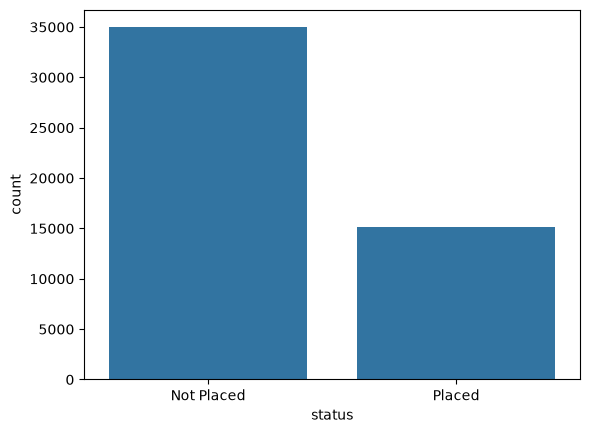

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(
    x="status",
    data=df
)

plt.show()

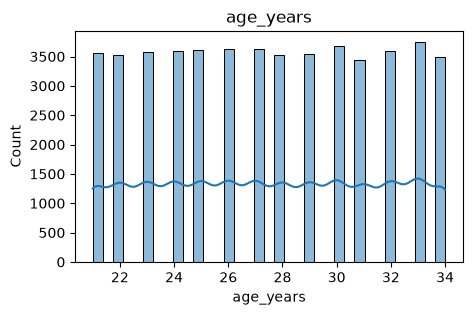

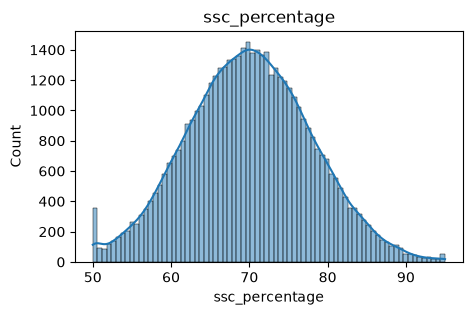

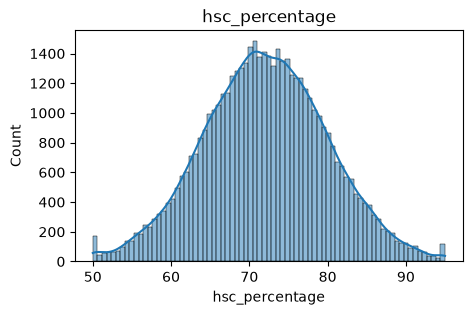

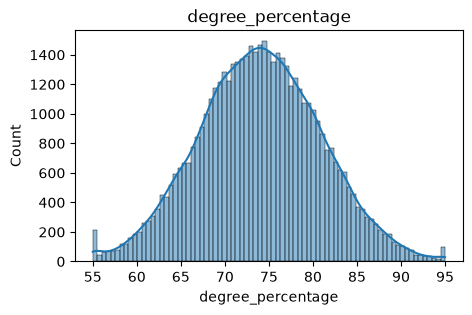

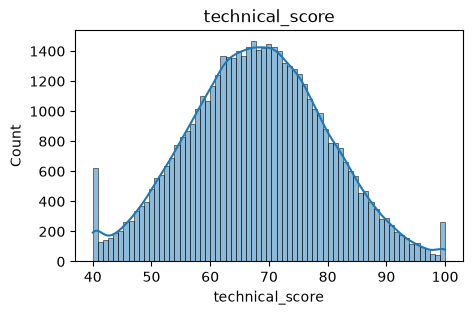

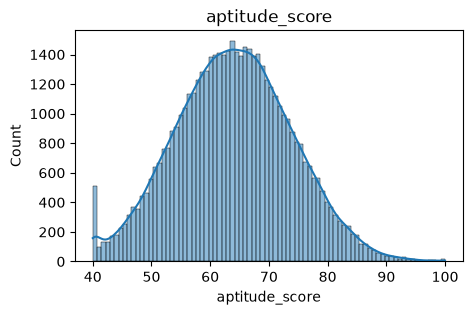

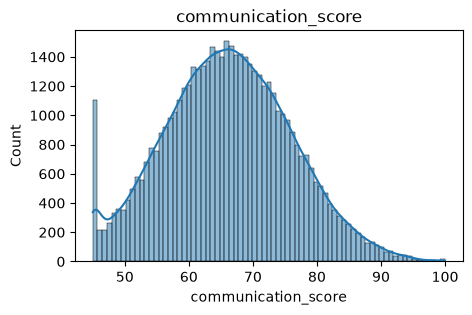

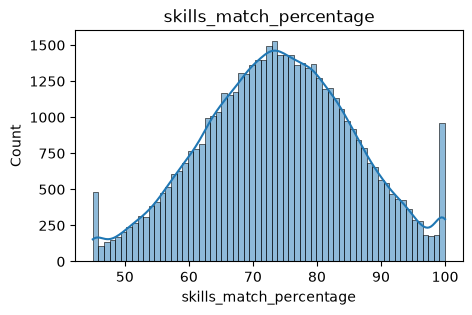

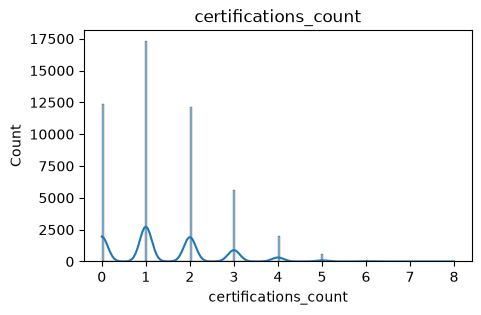

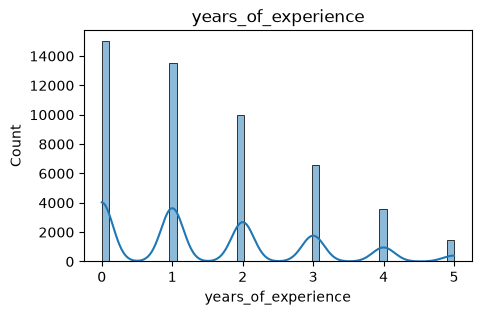

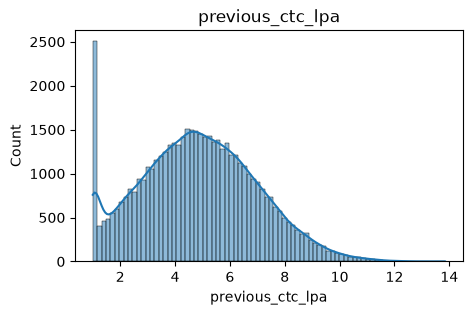

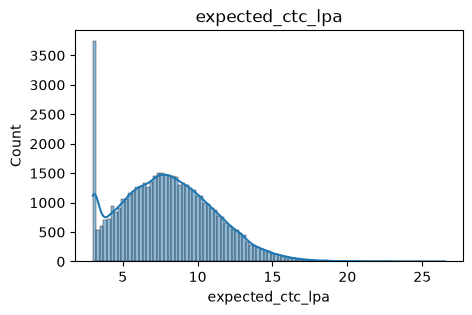

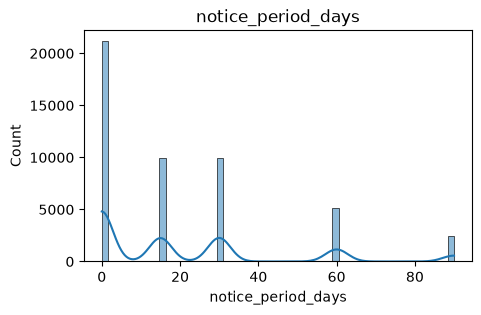

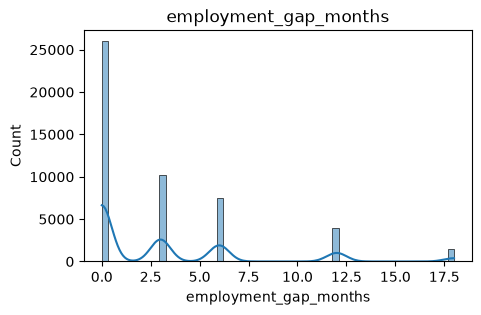

In [14]:
numeric_df = df.select_dtypes(
    include="number"
)

for col in numeric_df.columns:

    plt.figure(figsize=(5,3))

    sns.histplot(
        df[col],
        kde=True
    )

    plt.title(col)

    plt.show()

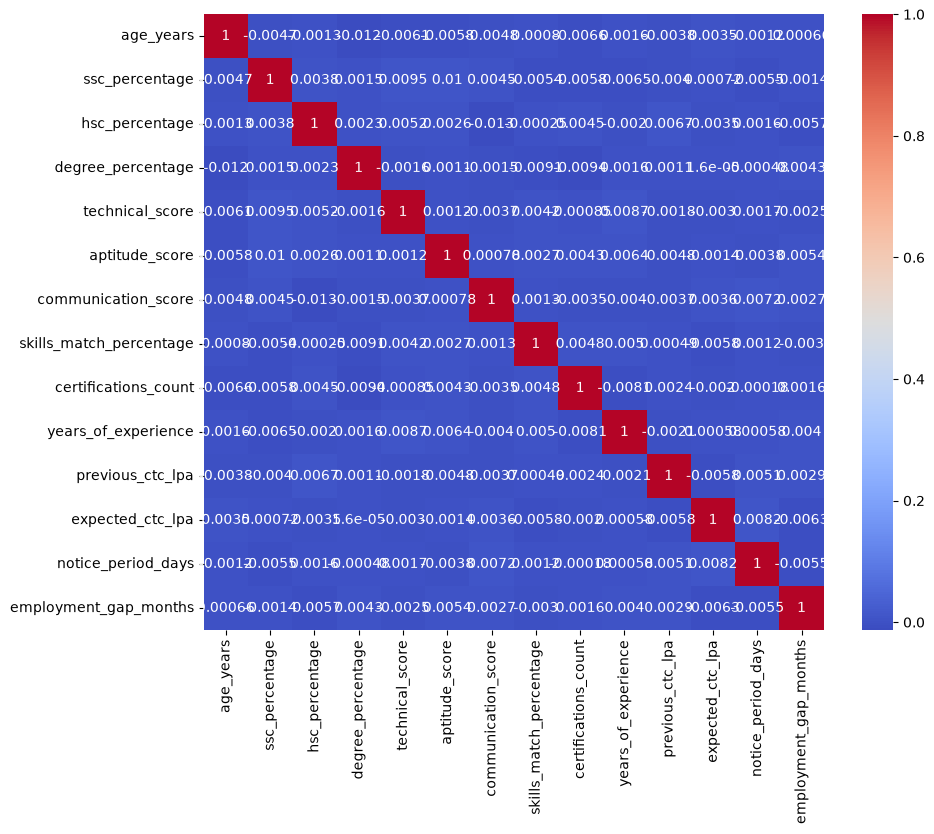

In [15]:
plt.figure(figsize=(10,8))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    annot=True
)

plt.show()

In [16]:
cat_cols = df.select_dtypes(
    include=["object"]
).columns

for col in cat_cols:
    
    df[col] = df[col].fillna(
        df[col].mode()[0]
    )

C:\Users\User\AppData\Local\Temp\ipykernel_14504\1005256884.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(


In [17]:
num_cols = [
    "ssc_percentage",
    "hsc_percentage",
    "notice_period_days",
    "employment_gap_months"
]

for col in num_cols:

    df[col] = df[col].fillna(
        df[col].median()
    )

In [18]:
from sklearn.preprocessing import LabelEncoder

In [19]:
cat_cols = [
    'gender',
    'degree_specialization',
    'internship_experience',
    'career_switch_willingness',
    'relevant_experience',
    'company_tier',
    'job_role_match',
    'competition_level',
    'bond_requirement',
    'layoff_history',
    'relocation_willingness',
    'status'
]

for col in cat_cols:

    le = LabelEncoder()

    df[col] = le.fit_transform(
        df[col]
    )

In [20]:
X = df.drop(
    "status",
    axis=1
)

y = df["status"]

In [21]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [22]:
scale_cols = [
    'age_years',
    'ssc_percentage',
    'hsc_percentage',
    'degree_percentage',
    'technical_score',
    'aptitude_score',
    'communication_score',
    'skills_match_percentage',
    'certifications_count',
    'years_of_experience',
    'previous_ctc_lpa',
    'expected_ctc_lpa',
    'notice_period_days',
    'employment_gap_months'
]

In [23]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train[scale_cols] = scaler.fit_transform(
    X_train[scale_cols]
)

X_test[scale_cols] = scaler.transform(
    X_test[scale_cols]
)

In [24]:
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [25]:


models = {

    "Logistic Regression":
    LogisticRegression(),

    "KNN":
    KNeighborsClassifier(),

    "Decision Tree":
    DecisionTreeClassifier(),

    "Random Forest":
    RandomForestClassifier()
}

In [26]:
for name, model in models.items():

    model.fit(
        X_train,
        y_train
    )

    score = model.score(
        X_test,
        y_test
    )

    print(
        f"{name}: {score:.4f}"
    )

Logistic Regression: 0.8615
KNN: 0.7906
Decision Tree: 0.8259
Random Forest: 0.8867


In [27]:
rf = RandomForestClassifier(
    random_state=42
)

scores = cross_val_score(
    rf,
    X,
    y,
    cv=5
)

print(scores)

print(
    scores.mean()
)

[0.88987531 0.88698254 0.8878803  0.89256858 0.88976457]
0.8894142596421954


In [28]:
params = {

    "n_estimators":
    [100,200],

    "max_depth":
    [5,10]
}

In [29]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

In [30]:
from sklearn.model_selection import train_test_split

X = df.drop('status', axis=1)   # Features
y = df['status']                # Target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [33]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier

X = df.drop('status', axis=1)
y = df['status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

params = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10]
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    params,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best Score:", grid.best_score_)

best_model = grid.best_estimator_

Best Parameters: {'max_depth': 10, 'n_estimators': 200}
Best Score: 0.8765554820106464


In [34]:
importance = pd.DataFrame({

    "Feature":
    X.columns,

    "Importance":
    best_model.feature_importances_
})

In [35]:
importance.sort_values(
    by="Importance",
    ascending=False
)

,Feature,Importance
6,technical_score,0.367998
12,years_of_experience,0.213418
9,skills_match_percentage,0.095383
18,job_role_match,0.060787
16,expected_ctc_lpa,0.056512
11,internship_experience,0.037430
8,communication_score,0.028639
15,previous_ctc_lpa,0.026292
22,layoff_history,0.022050
14,relevant_experience,0.016791


In [41]:
import joblib

In [42]:
joblib.dump(
    best_model,
    "placement_prediction_model.pkl"
)

['placement_prediction_model.pkl']

In [43]:
new_candidate = pd.DataFrame(
    [[
        0.25,1,-0.45,0.32,0.41,
        2,0.75,0.60,0.22,0.55,
        1.10,0.30,-0.20,0.50,-0.10,
        0.00,1,1,0,2,1,0,1,0,1
    ]],
    columns=X.columns
)

prediction = model.predict(
    new_candidate
)

print(prediction)

[0]


In [39]:
def generate_automated_report(df, output_pdf):
    print("Generating report...")
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])

In [40]:
generate_automated_report(
    df,
    output_pdf="Placement_Analysis_Report.pdf"
)

Generating report...
Rows: 50124
Columns: 26
